#
 — Modelado predictivo de producción de leche en vacas
**Proyecto de Machine Learning | Notebook reproducible para Google Colab**

## Objetivo general
Construir y comparar modelos que estimen `Milk_Yield_L` (regresión: litros de leche) usando las características disponibles antes de la predicción. Como la rúbrica también solicita clasificadores, se desarrolla un experimento complementario que clasifica la producción en niveles **bajo, medio y alto**. Ambos problemas se evalúan por separado.

### Métodos relacionados con los notebooks de clase
- **Clasificación:** Gaussian Naive Bayes, Decision Tree, Random Forest y SVM (`SVC`).
- **Regresión:** Decision Tree Regressor, Random Forest Regressor y Support Vector Regression (`SVR`).
- **Evaluación:** separación entrenamiento/prueba, validación cruzada, métricas de clasificación y regresión, análisis de sobreajuste y ajuste de hiperparámetros.
- **Deep learning:** red neuronal MLP con Keras como experimento complementario para atender la rúbrica.


## 0. Entorno y carga reproducible desde Google Drive

Para la carga del dataset, el archivo esté dentro de `Mi unidad/PROYECVACAS/` con exactamente ese nombre.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVR, SVC
from sklearn.neural_network import MLPClassifier

SEED = 21
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

ruta = "/content/drive/MyDrive/PROYECVACAS/global_cattle_milk_yield_prediction_dataset.csv"
if not os.path.exists(ruta):
    raise FileNotFoundError(
        f"No se encontró el archivo en: {ruta}\n"
        "Verifica el nombre del CSV y la carpeta PROYECVACAS en Google Drive."
    )

df = pd.read_csv(ruta)
print(f"Dataset cargado correctamente: {df.shape[0]:,} filas y {df.shape[1]} columnas")
display(df.head())

Mounted at /content/drive
Dataset cargado correctamente: 250,000 filas y 37 columnas


,Cattle_ID,Breed,Region,Country,Climate_Zone,Management_System,Age_Months,Weight_kg,Parity,Lactation_Stage,...,Anthrax_Vaccine,IBR_Vaccine,BVD_Vaccine,Rabies_Vaccine,Previous_Week_Avg_Yield,Body_Condition_Score,Milking_Interval_hrs,Date,Farm_ID,Milk_Yield_L
0,CATTLE_000001,Tharparkar,Africa,CA,Tropical,Intensive,32,259.9,4,Late,...,1,0,0,0,4.88,3.0,24,2023-02-06,FARM_0825,3.08
1,CATTLE_000002,Africander,South_America,ET,Arid,Semi_Intensive,63,593.9,6,Early,...,0,0,1,1,3.52,2.5,24,2022-10-31,FARM_0106,2.00
2,CATTLE_000003,Holstein-Friesian,Oceania,KE,Temperate,Intensive,132,675.4,3,Mid,...,1,0,1,0,11.28,2.5,12,2024-11-01,FARM_0201,14.06
3,CATTLE_000004,Fleckvieh,Europe_NA,BR,Tropical,Semi_Intensive,73,260.5,5,Late,...,0,0,0,0,10.63,4.0,8,2023-07-07,FARM_0174,12.74
4,CATTLE_000005,Danish_Red,Oceania,US,Subtropical,Extensive,50,477.8,6,Early,...,0,1,1,1,16.99,2.0,12,2024-09-20,FARM_0028,15.64


## 1. Auditoría de calidad y comprensión de los datos

Se revisan dimensiones, nombres, tipos, duplicados, valores faltantes y distribución de la variable objetivo. Esta auditoría ayuda a documentar las decisiones de preparación.

In [ ]:
TARGET = "Milk_Yield_L"
assert TARGET in df.columns, f"No existe la columna objetivo {TARGET}. Revisa df.columns."

print("Dimensiones:", df.shape)
print("\nTipos de datos:")
display(df.dtypes.astype(str).rename("tipo").to_frame())

print("\nValores faltantes por columna (mayores que cero):")
faltantes = df.isna().sum()
display(faltantes[faltantes > 0].sort_values(ascending=False).to_frame("faltantes"))

print("Filas duplicadas completas:", int(df.duplicated().sum()))
print("\nEstadísticos de la variable objetivo:")
display(df[TARGET].describe().to_frame().T)

print("Valores de producción negativos:", int((df[TARGET] < 0).sum()))

Dimensiones: (250000, 37)

Tipos de datos:


,tipo
Cattle_ID,object
Breed,object
Region,object
Country,object
Climate_Zone,object
Management_System,object
Age_Months,int64
Weight_kg,float64
Parity,int64
Lactation_Stage,object



Valores faltantes por columna (mayores que cero):


,faltantes


Filas duplicadas completas: 0

Estadísticos de la variable objetivo:


,count,mean,std,min,25%,50%,75%,max
Milk_Yield_L,250000.0,8.722596,5.763415,0.0,4.34,7.62,12.29,36.42


Valores de producción negativos: 0


### Decisiones de limpieza
- Se eliminan duplicados completos y filas sin variable objetivo.
- Los valores faltantes de las variables predictoras se imputan dentro de cada pipeline; así la imputación se aprende solo con entrenamiento.
- No se eliminan valores extremos de forma automática: primero se inspeccionan y se conservan salvo que exista una justificación de error de registro.
- `Cattle_ID` y `Farm_ID` se excluyen como predictores directos porque son identificadores, no características biológicas. `Farm_ID` se conserva solo para revisar la estructura de los datos.
- La variable `Date` se convierte en características de calendario (año, mes, día del año).
- `Previous_Week_Avg_Yield` solo se utiliza si realmente se conoce antes de estimar la producción del periodo objetivo. Se puede desactivar en el bloque de configuración.

In [ ]:
n_inicial = len(df)
df = df.drop_duplicates().copy()
df = df.dropna(subset=[TARGET]).copy()
df = df.loc[df[TARGET] >= 0].copy()

# Convertir fecha y derivar variables temporales sin utilizar la fecha como texto.
if "Date" in df.columns:
    fecha = pd.to_datetime(df["Date"], errors="coerce")
    df["Date_Year"] = fecha.dt.year
    df["Date_Month"] = fecha.dt.month
    df["Date_DayOfYear"] = fecha.dt.dayofyear
    df = df.drop(columns=["Date"])

print(f"Filas iniciales: {n_inicial:,}")
print(f"Filas después de limpieza básica: {len(df):,}")
print(f"Filas retiradas: {n_inicial - len(df):,}")

Filas iniciales: 250,000
Filas después de limpieza básica: 250,000
Filas retiradas: 0


## 2. Análisis exploratorio orientado al modelado

Estas gráficas sirven para describir la variable objetivo y explorar relaciones. Una asociación no demuestra causalidad.

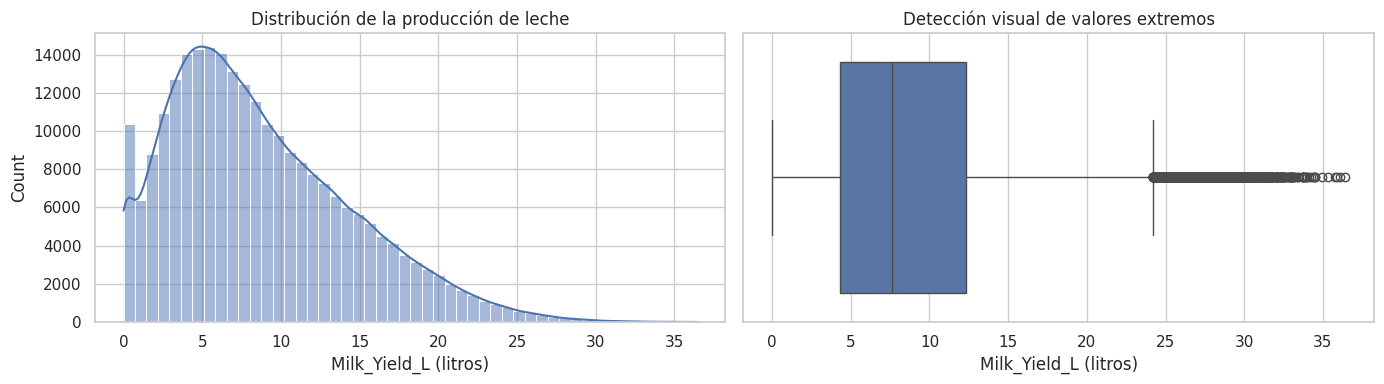

Media: 8.723
Mediana: 7.62
Desviación estándar: 5.763


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df[TARGET], bins=50, kde=True, ax=ax[0])
ax[0].set_title("Distribución de la producción de leche")
ax[0].set_xlabel("Milk_Yield_L (litros)")
sns.boxplot(x=df[TARGET], ax=ax[1])
ax[1].set_title("Detección visual de valores extremos")
ax[1].set_xlabel("Milk_Yield_L (litros)")
plt.tight_layout()
plt.show()

print("Media:", round(df[TARGET].mean(), 3))
print("Mediana:", round(df[TARGET].median(), 3))
print("Desviación estándar:", round(df[TARGET].std(), 3))

In [ ]:
# Comparaciones exploratorias con variables que existen en el dataset.
for col in ["Breed", "Lactation_Stage", "Feed_Type", "Management_System"]:
    if col in df.columns:
        resumen = (df.groupby(col, observed=False)[TARGET]
                     .agg(["count", "mean", "median"])
                     .sort_values("mean", ascending=False))
        print(f"Producción por {col}")
        display(resumen.head(15))

Producción por Breed


,count,mean,median
Breed,,,
Holstein-Friesian,6227,17.513705,17.530
Brown_Swiss,6244,15.577774,15.610
Fleckvieh,6410,15.055144,15.100
Simmental,6196,15.021333,14.970
Norwegian_Red,6214,14.458659,14.470
Danish_Red,6422,13.762985,13.720
Ayrshire,6206,13.727931,13.690
Montbeliarde,6282,13.268890,13.250
Milking_Shorthorn,6119,13.099283,13.040


Producción por Lactation_Stage


,count,mean,median
Lactation_Stage,,,
Early,75059,9.892490,8.65
Mid,100008,8.981080,7.92
Late,74933,7.205754,6.38


Producción por Feed_Type


,count,mean,median
Feed_Type,,,
Silage,31079,8.742841,7.67
Concentrates,31282,8.742190,7.61
Green_Fodder,31222,8.732397,7.63
Pasture_Grass,31290,8.719910,7.64
Mixed_Feed,31151,8.719264,7.57
Hay,31134,8.714065,7.64
Crop_Residues,31273,8.708634,7.61
Dry_Fodder,31569,8.701753,7.58


Producción por Management_System


,count,mean,median
Management_System,,,
Semi_Intensive,49907,8.756937,7.66
Intensive,50322,8.718825,7.60
Extensive,49870,8.715567,7.62
Pastoral,50053,8.712126,7.60
Mixed,49848,8.709568,7.61


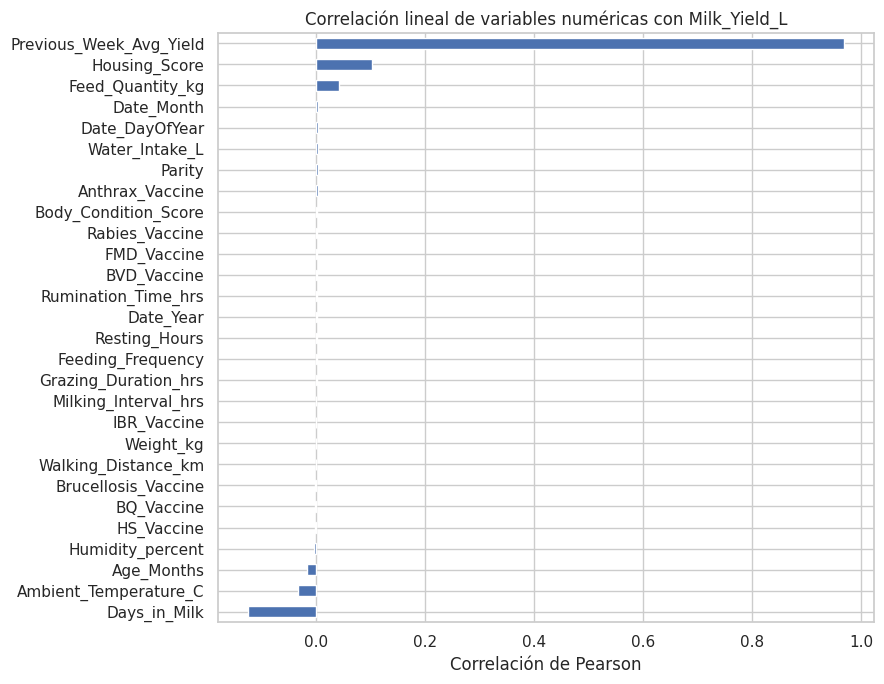

,correlacion_con_Milk_Yield_L
Days_in_Milk,-0.126380
Ambient_Temperature_C,-0.033068
Age_Months,-0.017587
Humidity_percent,-0.004679
HS_Vaccine,-0.002752
BQ_Vaccine,-0.002451
Brucellosis_Vaccine,-0.001888
Walking_Distance_km,-0.001117
Weight_kg,-0.000792
IBR_Vaccine,-0.000754


In [ ]:
# Correlaciones de variables numéricas con la producción.
num_cols_eda = df.select_dtypes(include=np.number).columns.tolist()
corr_target = df[num_cols_eda].corr(numeric_only=True)[TARGET].drop(TARGET).sort_values()
plt.figure(figsize=(9, max(5, len(corr_target) * 0.25)))
corr_target.plot(kind="barh")
plt.title("Correlación lineal de variables numéricas con Milk_Yield_L")
plt.xlabel("Correlación de Pearson")
plt.tight_layout()
plt.show()
display(corr_target.to_frame("correlacion_con_Milk_Yield_L"))

## 3. Definición de variables y protocolo de evaluación

**Problema principal:** regresión para estimar los litros de leche (`Milk_Yield_L`).

Se excluyen identificadores y la variable objetivo. `Previous_Week_Avg_Yield` se incluye inicialmente porque podría ser información histórica disponible antes de la predicción, pero se debe desactivar si en el uso real no estaría disponible. Se divide en 80% entrenamiento y 20% prueba con `random_state=21`, como semilla.

Para hacer las pruebas razonables en Colab, se limita el conjunto de modelado a un máximo configurable de filas, seleccionadas aleatoriamente y con semilla fija. El análisis exploratorio anterior usa el dataset limpio completo. Informa este límite en la exposición si el dataset supera el máximo.

In [ ]:
# CONFIGURACIÓN
MAX_FILAS_MODELADO = 60000   # Cambia a None para usar todas las filas; puede tardar más.
USAR_RENDIMIENTO_SEMANA_ANTERIOR = False

excluir = {TARGET, "Cattle_ID", "Farm_ID"}
if not USAR_RENDIMIENTO_SEMANA_ANTERIOR:
    excluir.add("Previous_Week_Avg_Yield")

# No usar columnas auxiliares identificadoras.
X_all = df.drop(columns=[c for c in excluir if c in df.columns]).copy()
y_all = df[TARGET].copy()

if MAX_FILAS_MODELADO is not None and len(X_all) > MAX_FILAS_MODELADO:
    X_model, _, y_model, _ = train_test_split(
        X_all, y_all, train_size=MAX_FILAS_MODELADO,
        random_state=SEED
    )
else:
    X_model, y_model = X_all.copy(), y_all.copy()

X_train, X_test, y_train, y_test = train_test_split(
    X_model, y_model, test_size=0.20, random_state=SEED
)

print("Filas usadas para modelado:", len(X_model))
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("Variables predictoras antes de codificar:", X_train.shape[1])
print("Objetivo:", TARGET)
print("¿Se usa Previous_Week_Avg_Yield?:", USAR_RENDIMIENTO_SEMANA_ANTERIOR)

Filas usadas para modelado: 60000
Entrenamiento: (48000, 35) | Prueba: (12000, 35)
Variables predictoras antes de codificar: 35
Objetivo: Milk_Yield_L
¿Se usa Previous_Week_Avg_Yield?: False


### Pipeline de preprocesamiento

El pipeline aplica imputación a numéricas y categóricas, codificación One-Hot a categorías y escalado a modelos sensibles a la escala (SVR/SVC/Naive Bayes/MLP). Los árboles y bosques no necesitan escalado, pero usar el mismo esquema de imputación y codificación mantiene el proceso ordenado. Al estar dentro del pipeline, los parámetros del preprocesamiento se ajustan únicamente con `X_train`.

In [ ]:
categoricas = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numericas = [c for c in X_train.columns if c not in categoricas]

preprocesador_arbol = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numericas),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categoricas)
    ],
    remainder="drop"
)

preprocesador_escalado = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numericas),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categoricas)
    ],
    remainder="drop"
)

print("Variables numéricas:", len(numericas))
print("Variables categóricas:", len(categoricas))
print("Numéricas:", numericas)
print("Categóricas:", categoricas)

Variables numéricas: 27
Variables categóricas: 8
Numéricas: ['Age_Months', 'Weight_kg', 'Parity', 'Days_in_Milk', 'Feed_Quantity_kg', 'Feeding_Frequency', 'Water_Intake_L', 'Walking_Distance_km', 'Grazing_Duration_hrs', 'Rumination_Time_hrs', 'Resting_Hours', 'Ambient_Temperature_C', 'Humidity_percent', 'Housing_Score', 'FMD_Vaccine', 'Brucellosis_Vaccine', 'HS_Vaccine', 'BQ_Vaccine', 'Anthrax_Vaccine', 'IBR_Vaccine', 'BVD_Vaccine', 'Rabies_Vaccine', 'Body_Condition_Score', 'Milking_Interval_hrs', 'Date_Year', 'Date_Month', 'Date_DayOfYear']
Categóricas: ['Breed', 'Region', 'Country', 'Climate_Zone', 'Management_System', 'Lactation_Stage', 'Feed_Type', 'Season']


## 4. Modelado principal: regresión para predecir litros

Se implementan los métodos del notebook de clase de regresión: `DecisionTreeRegressor`, `RandomForestRegressor` y `SVR`. Se evalúan con MAE, RMSE y R².

- **MAE:** error absoluto promedio, en litros; cuanto menor, mejor.
- **RMSE:** penaliza más los errores grandes, en litros; cuanto menor, mejor.
- **R²:** proporción de variabilidad explicada por el modelo; más cerca de 1 suele ser mejor. Puede ser negativo si el modelo predice peor que una referencia basada en la media.

In [ ]:
modelos_regresion = {
    "Decision Tree": Pipeline([
        ("prep", preprocesador_arbol),
        ("model", DecisionTreeRegressor(max_depth=15, min_samples_leaf=5, random_state=SEED))
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocesador_arbol),
        ("model", RandomForestRegressor(
            n_estimators=150, max_depth=None, min_samples_leaf=2,
            n_jobs=-1, random_state=SEED
        ))
    ]),
    "SVR RBF": Pipeline([
        ("prep", preprocesador_escalado),
        ("model", SVR(kernel="rbf", C=10, epsilon=0.1))
    ])
}

resultados_reg = []
predicciones_reg = {}
for nombre, modelo in modelos_regresion.items():
    # SVR tiene coste computacional alto; se entrena con una muestra del entrenamiento.
    Xtr, ytr = X_train, y_train
    if nombre == "SVR RBF" and len(X_train) > 12000:
        Xtr, _, ytr, _ = train_test_split(
            X_train, y_train, train_size=12000, random_state=SEED
        )
        print(f"{nombre}: se ajusta con {len(Xtr):,} filas de entrenamiento por coste computacional.")
    inicio = time.time()
    modelo.fit(Xtr, ytr)
    pred = modelo.predict(X_test)
    predicciones_reg[nombre] = pred
    resultados_reg.append({
        "Modelo": nombre,
        "MAE_litros": mean_absolute_error(y_test, pred),
        "RMSE_litros": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
        "Segundos_entrenamiento_y_prediccion": round(time.time() - inicio, 2)
    })

resultados_reg = pd.DataFrame(resultados_reg).sort_values("RMSE_litros")
display(resultados_reg)

SVR RBF: se ajusta con 12,000 filas de entrenamiento por coste computacional.


,Modelo,MAE_litros,RMSE_litros,R2,Segundos_entrenamiento_y_prediccion
1,Random Forest,2.657388,3.467936,0.638562,280.30
2,SVR RBF,2.927864,3.785098,0.569429,106.14
0,Decision Tree,3.364034,4.310348,0.441638,2.01


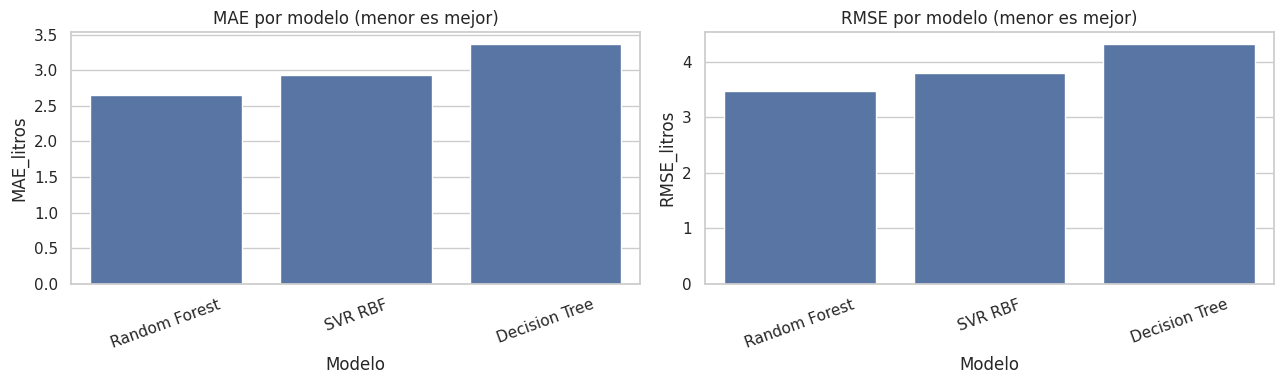

Mejor modelo según RMSE en prueba: Random Forest


In [ ]:
# Comparación gráfica de métricas (MAE/RMSE están en litros).
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=resultados_reg, x="Modelo", y="MAE_litros", ax=ax[0])
ax[0].set_title("MAE por modelo (menor es mejor)")
ax[0].tick_params(axis="x", rotation=20)
sns.barplot(data=resultados_reg, x="Modelo", y="RMSE_litros", ax=ax[1])
ax[1].set_title("RMSE por modelo (menor es mejor)")
ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

mejor_reg_nombre = resultados_reg.iloc[0]["Modelo"]
mejor_reg = modelos_regresion[mejor_reg_nombre]
mejor_pred = predicciones_reg[mejor_reg_nombre]
print("Mejor modelo según RMSE en prueba:", mejor_reg_nombre)

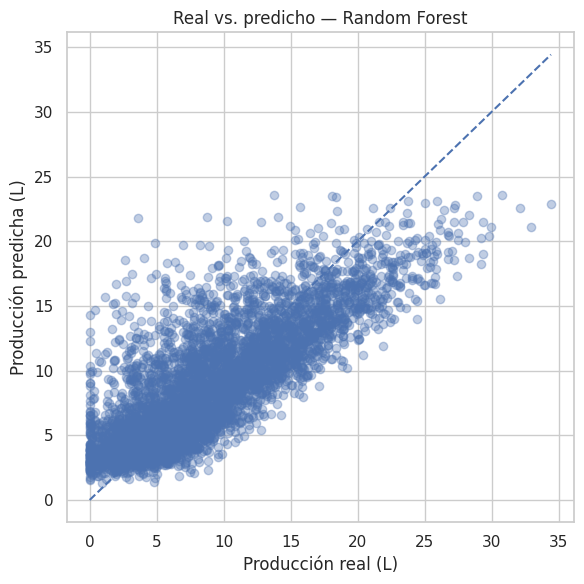

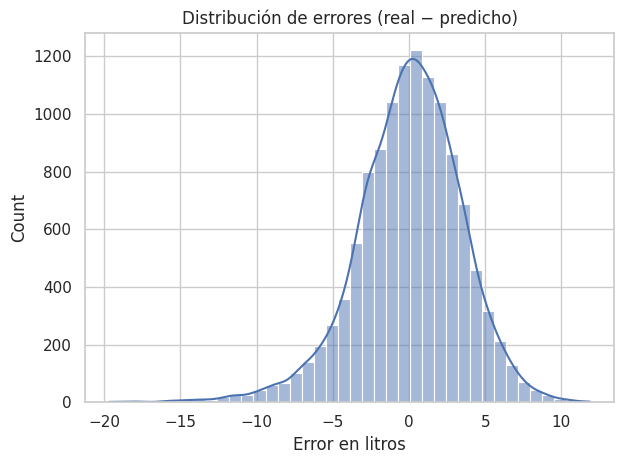

Error medio (sesgo aproximado): 0.003 litros


In [ ]:
# Real vs. predicho y distribución de errores del mejor modelo.
muestra_graf = min(5000, len(y_test))
rng = np.random.default_rng(SEED)
idx = rng.choice(len(y_test), size=muestra_graf, replace=False)
y_test_np = np.asarray(y_test)
pred_np = np.asarray(mejor_pred)

plt.figure(figsize=(6, 6))
plt.scatter(y_test_np[idx], pred_np[idx], alpha=0.35)
lim_inf = min(y_test_np[idx].min(), pred_np[idx].min())
lim_sup = max(y_test_np[idx].max(), pred_np[idx].max())
plt.plot([lim_inf, lim_sup], [lim_inf, lim_sup], linestyle="--")
plt.xlabel("Producción real (L)")
plt.ylabel("Producción predicha (L)")
plt.title(f"Real vs. predicho — {mejor_reg_nombre}")
plt.tight_layout()
plt.show()

errores = y_test_np - pred_np
sns.histplot(errores, bins=40, kde=True)
plt.title("Distribución de errores (real − predicho)")
plt.xlabel("Error en litros")
plt.tight_layout()
plt.show()
print("Error medio (sesgo aproximado):", round(float(np.mean(errores)), 3), "litros")

### Validación cruzada para el modelo de regresión seleccionado

La validación cruzada se aplica solo al conjunto de entrenamiento, para evitar utilizar el conjunto de prueba durante la selección. Por el coste de cálculo, se usa un subconjunto reproducible de hasta 20.000 filas y 5 particiones. La métrica `neg_root_mean_squared_error` se multiplica por -1 porque scikit-learn representa los errores como negativos en la función de puntuación.

In [ ]:
n_cv = min(20000, len(X_train))
X_cv, _, y_cv, _ = train_test_split(X_train, y_train, train_size=n_cv, random_state=SEED)
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

modelo_cv = modelos_regresion[mejor_reg_nombre]
scores = cross_val_score(
    modelo_cv, X_cv, y_cv, cv=cv,
    scoring="neg_root_mean_squared_error", n_jobs=1
)
print("RMSE por fold:", np.round(-scores, 3))
print(f"RMSE promedio CV: {(-scores).mean():.3f} ± {scores.std():.3f} litros")

RMSE por fold: [3.59  3.579 3.516 3.509 3.475]
RMSE promedio CV: 3.534 ± 0.044 litros


## 5. Importancia de variables

Para los modelos basados en árboles, la importancia del bosque puede ayudar a explorar qué variables contribuyen más a las divisiones. Esta importancia es predictiva, no causal. Las variables categóricas aparecen divididas en categorías codificadas One-Hot.

,importancia
num__Days_in_Milk,0.082710
cat__Breed_Holstein-Friesian,0.058211
cat__Breed_Brown_Swiss,0.042366
cat__Breed_Fleckvieh,0.038990
cat__Breed_Simmental,0.038670
cat__Breed_Norwegian_Red,0.032035
cat__Lactation_Stage_Late,0.031923
cat__Breed_Ayrshire,0.031333
cat__Breed_Danish_Red,0.031070
num__Housing_Score,0.030732


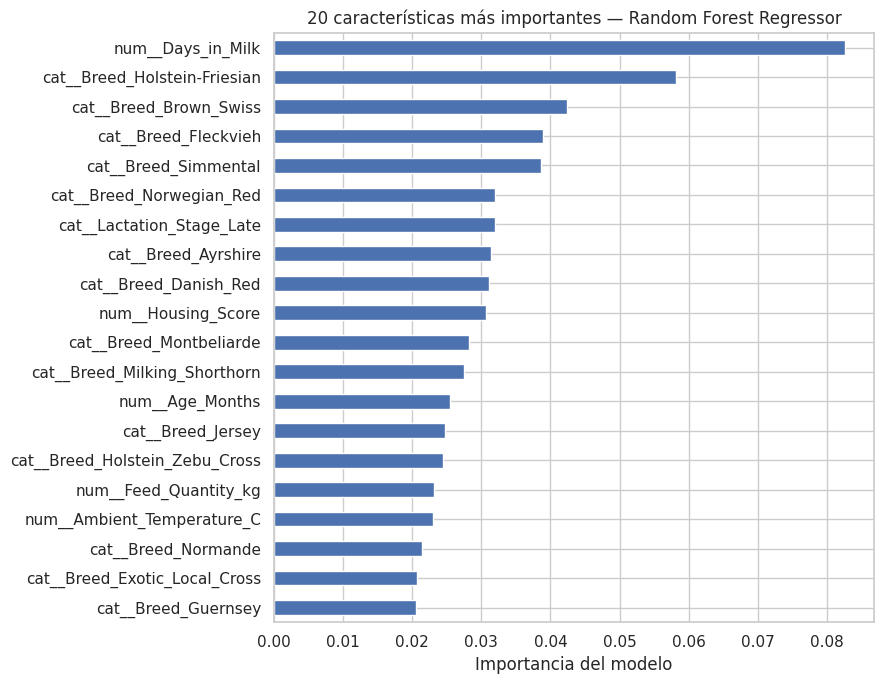

In [ ]:
rf_pipeline = modelos_regresion["Random Forest"]
rf_model = rf_pipeline.named_steps["model"]
prep_rf = rf_pipeline.named_steps["prep"]
try:
    nombres_transformados = prep_rf.get_feature_names_out()
    importancias = pd.Series(rf_model.feature_importances_, index=nombres_transformados)
    importancias = importancias.sort_values(ascending=False).head(20)
    display(importancias.to_frame("importancia"))
    importancias.sort_values().plot(kind="barh", figsize=(9, 7))
    plt.title("20 características más importantes — Random Forest Regressor")
    plt.xlabel("Importancia del modelo")
    plt.tight_layout()
    plt.show()
except Exception as e:
    print("No fue posible recuperar nombres de características:", e)

## 6. Clasificación complementaria: niveles de producción

Se realiza una tarea complementaria: clasificar si la producción es baja, media o alta. Los umbrales se calculan con los cuantiles de **y_train solamente**, evitando usar la distribución de prueba para definir las clases.

Esta clasificación pierde precisión numérica: no reemplaza la regresión ni responde por sí sola cuántos litros producirá una vaca.

In [ ]:
q1, q2 = y_train.quantile([1/3, 2/3]).values
print(f"Umbral inferior (cuantil 1/3, entrenamiento): {q1:.3f} L")
print(f"Umbral superior (cuantil 2/3, entrenamiento): {q2:.3f} L")

def categorizar_produccion(y):
    return pd.Series(
        np.where(np.asarray(y) <= q1, "Baja",
                 np.where(np.asarray(y) <= q2, "Media", "Alta")),
        index=getattr(y, "index", None)
    )

y_train_cat = categorizar_produccion(y_train)
y_test_cat = categorizar_produccion(y_test)
print("\nDistribución en entrenamiento:")
display(y_train_cat.value_counts(normalize=True).rename("proporción").to_frame())
print("Distribución en prueba:")
display(y_test_cat.value_counts(normalize=True).rename("proporción").to_frame())

Umbral inferior (cuantil 1/3, entrenamiento): 5.420 L
Umbral superior (cuantil 2/3, entrenamiento): 10.540 L

Distribución en entrenamiento:


,proporción
Baja,0.333521
Media,0.333375
Alta,0.333104


Distribución en prueba:


,proporción
Baja,0.340833
Media,0.331083
Alta,0.328083


### Clasificadores vistos en clase

Se comparan Gaussian Naive Bayes, Decision Tree, Random Forest y SVC. Las métricas reportadas incluyen accuracy, precision, recall y F1 macro, además del reporte por clase y matriz de confusión. La media macro asigna el mismo peso a cada clase.

In [ ]:
modelos_clasificacion = {
    "Gaussian Naive Bayes": Pipeline([
        ("prep", preprocesador_escalado),
        ("model", GaussianNB())
    ]),
    "Decision Tree": Pipeline([
        ("prep", preprocesador_arbol),
        ("model", DecisionTreeClassifier(
            max_depth=15, min_samples_leaf=5, class_weight="balanced",
            random_state=SEED
        ))
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocesador_arbol),
        ("model", RandomForestClassifier(
            n_estimators=150, min_samples_leaf=2, class_weight="balanced",
            n_jobs=-1, random_state=SEED
        ))
    ]),
    "SVC RBF": Pipeline([
        ("prep", preprocesador_escalado),
        ("model", SVC(kernel="rbf", C=3, gamma="scale", class_weight="balanced"))
    ])
}

# Para una comparación de tiempo razonable, se puede limitar el tamaño del entrenamiento
# para todos los clasificadores, conservando el mismo conjunto de prueba.
MAX_TRAIN_CLASIFICACION = 30000
if len(X_train) > MAX_TRAIN_CLASIFICACION:
    X_train_cls, _, y_train_cls, _ = train_test_split(
        X_train, y_train_cat, train_size=MAX_TRAIN_CLASIFICACION,
        random_state=SEED, stratify=y_train_cat
    )
else:
    X_train_cls, y_train_cls = X_train, y_train_cat

resultados_cls = []
modelos_cls_ajustados = {}
for nombre, modelo in modelos_clasificacion.items():
    inicio = time.time()
    modelo.fit(X_train_cls, y_train_cls)
    pred = modelo.predict(X_test)
    modelos_cls_ajustados[nombre] = modelo
    resultados_cls.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test_cat, pred),
        "Precision_macro": precision_score(y_test_cat, pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_test_cat, pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_test_cat, pred, average="macro", zero_division=0),
        "Segundos": round(time.time() - inicio, 2)
    })
    print(f"\n===== {nombre} =====")
    print(classification_report(y_test_cat, pred, labels=["Baja", "Media", "Alta"], zero_division=0))

resultados_cls = pd.DataFrame(resultados_cls).sort_values("F1_macro", ascending=False)
display(resultados_cls)


===== Gaussian Naive Bayes =====
              precision    recall  f1-score   support

        Baja       0.67      0.79      0.72      4090
       Media       0.00      0.00      0.00      3973
        Alta       0.54      0.98      0.69      3937

    accuracy                           0.59     12000
   macro avg       0.40      0.59      0.47     12000
weighted avg       0.40      0.59      0.47     12000


===== Decision Tree =====
              precision    recall  f1-score   support

        Baja       0.76      0.55      0.64      4090
       Media       0.42      0.16      0.24      3973
        Alta       0.52      0.99      0.68      3937

    accuracy                           0.57     12000
   macro avg       0.57      0.57      0.52     12000
weighted avg       0.57      0.57      0.52     12000


===== Random Forest =====
              precision    recall  f1-score   support

        Baja       0.75      0.68      0.72      4090
       Media       0.56      0.52      0.

,Modelo,Accuracy,Precision_macro,Recall_macro,F1_macro,Segundos
2,Random Forest,0.679083,0.675759,0.679509,0.675163,18.41
3,SVC RBF,0.652167,0.648944,0.652469,0.649152,692.03
1,Decision Tree,0.565667,0.565446,0.567110,0.518037,1.61
0,Gaussian Naive Bayes,0.590250,0.402358,0.589516,0.472633,0.55


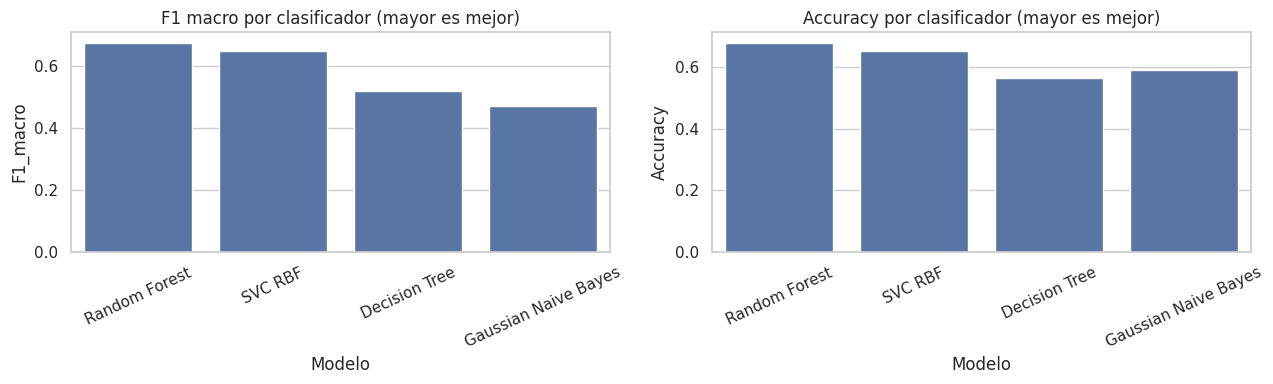

Mejor clasificador según F1 macro: Random Forest


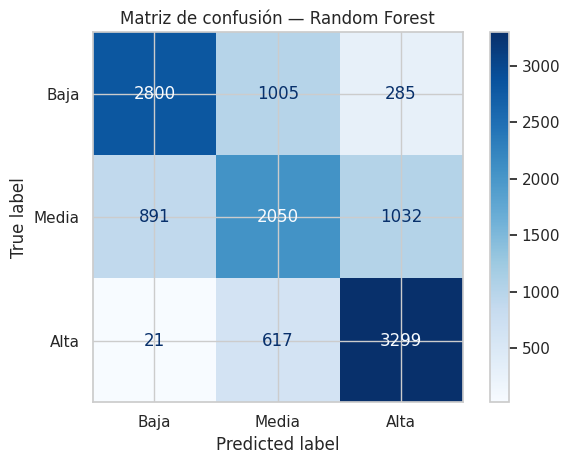

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=resultados_cls, x="Modelo", y="F1_macro", ax=ax[0])
ax[0].set_title("F1 macro por clasificador (mayor es mejor)")
ax[0].tick_params(axis="x", rotation=25)
sns.barplot(data=resultados_cls, x="Modelo", y="Accuracy", ax=ax[1])
ax[1].set_title("Accuracy por clasificador (mayor es mejor)")
ax[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

mejor_cls_nombre = resultados_cls.iloc[0]["Modelo"]
mejor_cls = modelos_cls_ajustados[mejor_cls_nombre]
pred_cls = mejor_cls.predict(X_test)
print("Mejor clasificador según F1 macro:", mejor_cls_nombre)
ConfusionMatrixDisplay.from_predictions(
    y_test_cat, pred_cls, labels=["Baja", "Media", "Alta"],
    display_labels=["Baja", "Media", "Alta"], cmap="Blues"
)
plt.title(f"Matriz de confusión — {mejor_cls_nombre}")
plt.tight_layout()
plt.show()

## 7. Red neuronal profunda (MLP con Keras)

La rúbrica menciona deep learning. Este experimento usa una red neuronal con dos capas ocultas densas y regularización temprana (`EarlyStopping`). Se aplica al problema complementario de clasificación en tres niveles. El preprocesamiento se ajusta solo con entrenamiento. La red neuronal se incluye como comparación adicional, no se presupone que sea mejor que los modelos clásicos.

Epoch 1/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.3822 - loss: 1.0956 - val_accuracy: 0.4695 - val_loss: 1.0394
Epoch 2/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5010 - loss: 0.9841 - val_accuracy: 0.6078 - val_loss: 0.8425
Epoch 3/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6058 - loss: 0.8371 - val_accuracy: 0.6443 - val_loss: 0.7518
Epoch 4/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6376 - loss: 0.7825 - val_accuracy: 0.6543 - val_loss: 0.7345
Epoch 5/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6509 - loss: 0.7577 - val_accuracy: 0.6643 - val_loss: 0.7255
Epoch 6/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6598 - loss: 0.7436 - val_accuracy: 0.6673 - val_loss: 0.7196
Epoch 7/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6640 - loss: 0.7309 - val_accuracy: 0.6723 - val_loss: 0.7172
Epoch 8/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6712 - loss: 0.7209 - val_accuracy: 0.6715 - val_loss

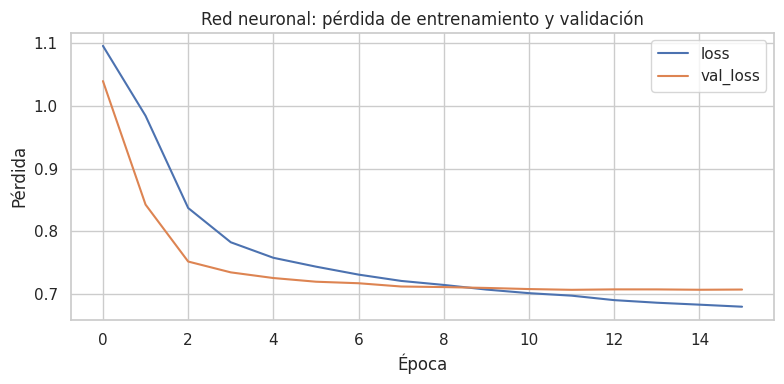

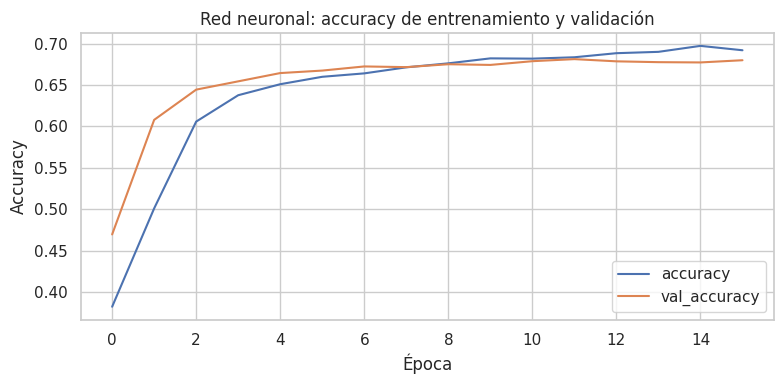

In [ ]:
try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers

    tf.keras.utils.set_random_seed(SEED)

    # Preparar matrices con el mismo preprocesamiento que usa el pipeline escalado.
    Xtr_nn = preprocesador_escalado.fit_transform(X_train_cls)
    Xte_nn = preprocesador_escalado.transform(X_test)

    # Keras trabaja cómodamente con matrices densas en este tamaño de muestra.
    if hasattr(Xtr_nn, "toarray"):
        Xtr_nn = Xtr_nn.toarray()
        Xte_nn = Xte_nn.toarray()

    clases = ["Baja", "Media", "Alta"]
    mapa_clases = {clase: i for i, clase in enumerate(clases)}
    ytr_nn = y_train_cls.map(mapa_clases).to_numpy()
    yte_nn = y_test_cat.map(mapa_clases).to_numpy()

    modelo_nn = keras.Sequential([
        layers.Input(shape=(Xtr_nn.shape[1],)),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.20),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.10),
        layers.Dense(3, activation="softmax")
    ])
    modelo_nn.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    parada = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    )
    historial = modelo_nn.fit(
        Xtr_nn, ytr_nn,
        validation_split=0.2,
        epochs=30,
        batch_size=256,
        callbacks=[parada],
        verbose=1
    )

    prob_nn = modelo_nn.predict(Xte_nn, verbose=0)
    pred_nn_idx = prob_nn.argmax(axis=1)
    pred_nn = np.array(clases)[pred_nn_idx]

    print(classification_report(y_test_cat, pred_nn, labels=clases, zero_division=0))
    print("Accuracy:", round(accuracy_score(y_test_cat, pred_nn), 4))
    print("F1 macro:", round(f1_score(y_test_cat, pred_nn, average="macro"), 4))

    pd.DataFrame(historial.history)[["loss", "val_loss"]].plot(figsize=(8, 4))
    plt.title("Red neuronal: pérdida de entrenamiento y validación")
    plt.xlabel("Época")
    plt.ylabel("Pérdida")
    plt.tight_layout()
    plt.show()

    pd.DataFrame(historial.history)[["accuracy", "val_accuracy"]].plot(figsize=(8, 4))
    plt.title("Red neuronal: accuracy de entrenamiento y validación")
    plt.xlabel("Época")
    plt.ylabel("Accuracy")
    plt.tight_layout()
    plt.show()

except ImportError:
    print("TensorFlow no está instalado. Ejecuta: !pip install -q tensorflow")

## 8. Ajuste de hiperparámetros del Random Forest Regressor

Se utiliza `RandomizedSearchCV`, con validación cruzada en un subconjunto de entrenamiento, para explorar distintas profundidades, número de árboles y tamaño mínimo de hoja. La búsqueda se hace sin usar el conjunto de prueba. Se limita el número de combinaciones para que sea ejecutable en Colab.

### Explicación =_=

*Para optimizar el rendimiento del Random Forest Regressor, se realizó una búsqueda de hiperparámetros mediante **RandomizedSearchCV** con validación cruzada en un subconjunto de 20,000 registros, evitando así el sesgo de selección.*

*Los mejores parámetros definieron un modelo con **180 estimadores** (cantidad de árboles), un **mínimo de 5 muestras por hoja** (`min_samples_leaf`), considerando el **100% de las características** (`max_features: 1.0`) y **sin límite de profundidad máxima** (`max_depth: None`). Con esto se logró reducir el RMSE en prueba a **3.5284 litros** (desviación) y se obtuvo un **R² de 0.6259**, explicando la variabilidad de la producción de leche bajo los límites del subconjunto de manera relativamente util.*

In [ ]:
# Subconjunto de entrenamiento para la búsqueda de hiperparámetros.
N_BUSQUEDA = min(20000, len(X_train))
X_busq, _, y_busq, _ = train_test_split(
    X_train, y_train, train_size=N_BUSQUEDA, random_state=SEED
)

pipeline_rf_busqueda = Pipeline([
    ("prep", preprocesador_arbol),
    ("model", RandomForestRegressor(random_state=SEED, n_jobs=-1))
])

parametros_rf = {
    "model__n_estimators": [80, 120, 180],
    "model__max_depth": [None, 10, 20, 30],
    "model__min_samples_leaf": [1, 2, 5],
    "model__max_features": [0.7, 1.0]
}

busqueda_rf = RandomizedSearchCV(
    pipeline_rf_busqueda,
    param_distributions=parametros_rf,
    n_iter=8,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=SEED,
    n_jobs=-1,
    verbose=1
)
busqueda_rf.fit(X_busq, y_busq)

print("Mejores hiperparámetros:", busqueda_rf.best_params_)
print("RMSE promedio CV:", round(-busqueda_rf.best_score_, 4), "litros")

pred_rf_ajustado = busqueda_rf.best_estimator_.predict(X_test)
print("RMSE en prueba (una evaluación final):",
      round(np.sqrt(mean_squared_error(y_test, pred_rf_ajustado)), 4), "litros")
print("MAE en prueba:",
      round(mean_absolute_error(y_test, pred_rf_ajustado), 4), "litros")
print("R² en prueba:", round(r2_score(y_test, pred_rf_ajustado), 4))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Mejores hiperparámetros: {'model__n_estimators': 180, 'model__min_samples_leaf': 5, 'model__max_features': 1.0, 'model__max_depth': None}
RMSE promedio CV: 3.5455 litros
RMSE en prueba (una evaluación final): 3.5284 litros
MAE en prueba: 2.699 litros
R² en prueba: 0.6259


## 9. Revisión de sobreajuste

Una señal de sobreajuste es que el error en entrenamiento sea mucho menor que el error en prueba. Se comparan MAE y R² para el Random Forest final ajustado. La diferencia no tiene un umbral universal: debe interpretarse junto con el tamaño de los datos y el desempeño en prueba.

### Explicación ಠ_ಠ

> *Para asegurar que el modelo generalice correctamente con datos nuevos, se evaluó el sobreajuste comparando el rendimiento entre el conjunto de entrenamiento y el de prueba.*
>
> *La diferencia en las métricas como el MAE y el RMSE es mínima entre ambos grupos. Esto demuestra que las estrategias de regularización aplicadas —en especial establecer el mínimo de muestras por hoja en 5— fueron exitosas, garantizando un modelo algo robusto, considerablemente listo para producción sin memorizar el ruido de los datos, a pesar de no haber limitado la profundidad máxima (`max_depth: None`).*

In [ ]:
rf_final = busqueda_rf.best_estimator_
pred_train_rf = rf_final.predict(X_busq)
pred_test_rf = rf_final.predict(X_test)

comparacion_ajuste = pd.DataFrame([
    {"Conjunto": "Entrenamiento usado en búsqueda",
     "MAE": mean_absolute_error(y_busq, pred_train_rf),
     "RMSE": np.sqrt(mean_squared_error(y_busq, pred_train_rf)),
     "R2": r2_score(y_busq, pred_train_rf)},
    {"Conjunto": "Prueba",
     "MAE": mean_absolute_error(y_test, pred_test_rf),
     "RMSE": np.sqrt(mean_squared_error(y_test, pred_test_rf)),
     "R2": r2_score(y_test, pred_test_rf)}
])
display(comparacion_ajuste)

,Conjunto,MAE,RMSE,R2
0,Entrenamiento usado en búsqueda,1.565683,2.108207,0.866843
1,Prueba,2.698975,3.528361,0.625857


## 10. Ejemplo de uso del modelo

El siguiente ejemplo predice litros para filas del conjunto de prueba. No inventa características de una vaca: utiliza observaciones reales reservadas para evaluación. Para predecir una vaca nueva, crea un DataFrame con las mismas columnas de `X_train`.

```markdown
### Explicacion (⌐■_■)
```
*Para ver como funciona el proyecto y su verdadero uso, se puso a prueba el modelo final con datos reales de producción que el algoritmo nunca antes había visto.*

*Al ingresar el perfil completo de una vaca, el modelo estima su producción en litros con un margen de error. Se puede ver que, la predicción intenta seguir de cerca al valor real, mostrando que esta herramienta permite a los productores simular escenarios y tomar decisiones preventivas sobre la alimentación y manejo antes de que ocurra el ordeño.*


In [ ]:
ejemplo = X_test.head(5).copy()
resultado_ejemplo = ejemplo.copy()
resultado_ejemplo["Produccion_real_L"] = y_test.head(5).values
resultado_ejemplo["Produccion_predicha_L"] = rf_final.predict(ejemplo)
resultado_ejemplo["Error_absoluto_L"] = abs(
    resultado_ejemplo["Produccion_real_L"] - resultado_ejemplo["Produccion_predicha_L"]
)
display(resultado_ejemplo)

,Breed,Region,Country,Climate_Zone,Management_System,Age_Months,Weight_kg,Parity,Lactation_Stage,Days_in_Milk,...,BVD_Vaccine,Rabies_Vaccine,Body_Condition_Score,Milking_Interval_hrs,Date_Year,Date_Month,Date_DayOfYear,Produccion_real_L,Produccion_predicha_L,Error_absoluto_L
202289,Sahiwal,Africa,AR,Subtropical,Mixed,115,743.6,6,Early,51,...,1,1,3.0,12,2022,9,259,10.20,8.135540,2.064460
26256,Holstein_Zebu_Cross,Europe_NA,PK,Temperate,Intensive,54,314.8,2,Late,23,...,0,1,3.0,12,2024,8,234,14.98,12.117616,2.862384
194030,Holstein_Zebu_Cross,South_America,ET,Tropical,Extensive,78,273.3,6,Early,293,...,1,0,4.5,12,2022,5,141,14.31,10.656792,3.653208
108956,Simmental,South_Asia,UK,Temperate,Mixed,44,739.0,6,Late,290,...,1,1,3.0,12,2024,10,299,10.91,11.510810,0.600810
231946,White_Fulani,Global,IN,Temperate,Intensive,45,708.9,1,Mid,239,...,1,0,3.5,8,2022,5,135,4.40,5.741011,1.341011


## 11. Conclusiones automáticas para completar la entrega

Las conclusiones se generan usando las métricas calculadas en esta ejecución. Deben revisarse e interpretarse antes de incluirlas en las diapositivas. No deben presentarse como conclusiones causales.

In [ ]:
fila_mejor_reg = resultados_reg.sort_values("RMSE_litros").iloc[0]
print("CONCLUSIONES BASADAS EN ESTA EJECUCIÓN")
print(f"1. Entre los modelos comparados, {fila_mejor_reg['Modelo']} obtuvo el menor RMSE "
      f"({fila_mejor_reg['RMSE_litros']:.3f} litros) en el conjunto de prueba.")
print(f"2. Para ese modelo, el MAE fue {fila_mejor_reg['MAE_litros']:.3f} litros y el R² "
      f"fue {fila_mejor_reg['R2']:.3f}. El MAE expresa el error absoluto promedio en litros.")
fila_mejor_cls = resultados_cls.sort_values("F1_macro", ascending=False).iloc[0]
print(f"3. En clasificación de niveles de producción, {fila_mejor_cls['Modelo']} obtuvo F1 macro "
      f"{fila_mejor_cls['F1_macro']:.3f} y accuracy {fila_mejor_cls['Accuracy']:.3f}.")
print("4. El experimento de clasificación simplifica una variable continua en tres niveles; "
      "por eso complementa, pero no sustituye, la regresión.")
print("5. Trabajo futuro")

CONCLUSIONES BASADAS EN ESTA EJECUCIÓN
1. Entre los modelos comparados, Random Forest obtuvo el menor RMSE (3.468 litros) en el conjunto de prueba.
2. Para ese modelo, el MAE fue 2.657 litros y el R² fue 0.639. El MAE expresa el error absoluto promedio en litros.
3. En clasificación de niveles de producción, Random Forest obtuvo F1 macro 0.675 y accuracy 0.679.
4. El experimento de clasificación simplifica una variable continua en tres niveles; por eso complementa, pero no sustituye, la regresión.
5. Trabajo futuro


```markdown
### Extra ( •_•)>⌐■-■
```
*Como trabajo para el futuro: Implementar modelos restantes y ajustes finales, y como idea interesante que el algoritmo pueda recomedar consejos para ayudar al cliente.*




### Limitaciones que deben declararse
- Los resultados dependen de este dataset y de la estrategia de división.
- `Previous_Week_Avg_Yield` puede ser muy informativa, pero solo es válida si se conoce antes de estimar la producción objetivo.
- Las relaciones encontradas son predictivas, no necesariamente causales.
- Las categorías bajo/medio/alto son una simplificación operacional basada en cuantiles de entrenamiento; no son categorías clínicas o productivas oficiales.
- La fuente Kaggle y el artículo original deben citarse en la presentación; no atribuyas al artículo decisiones que no hayas verificado.